<h1/>Training Notebook to classify Chest XRay images into PA or L views</h1>

<h1/>0. Import libraries</h1>

In [1]:
import pandas as pd
from skimage.io import imread
from matplotlib import pyplot as plt
import time
import os
import copy

# AI framework
import torch
from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms
import torch.nn as nn
import torchxrayvision as xrv

# Visualize the evolution of the model during training
from torch.utils.tensorboard import SummaryWriter
writer = SummaryWriter()

# Statistical analysis on the test dataset:
import sklearn
from sklearn.metrics import confusion_matrix
import seaborn as sns
from sklearn.metrics import roc_auc_score, auc
from sklearn.metrics import roc_curve

# Device
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f'Device: {DEVICE}')

Device: cuda


<h1/>1. Import data and pre-processing</h1>

<h2/>1.1 Create a class to manage the dataset</h2>

In [2]:
# Define a personalized class for the dataset
class PadChestDataset(Dataset):
    def __init__(self, img_dir, csv_file, views = None, transform = None):
        self.labels = pd.read_csv(csv_file)
        
        # Remove missing files
        missing = ["216840111366964012819207061112010307142602253_04-014-084.png",
                   "216840111366964012989926673512011074122523403_00-163-058.png",
                   "216840111366964012959786098432011033083840143_00-176-115.png",
                   "216840111366964012558082906712009327122220177_00-102-064.png",
                   "216840111366964012339356563862009072111404053_00-043-192.png",
                   "216840111366964013076187734852011291090445391_00-196-188.png",
                   "216840111366964012373310883942009117084022290_00-064-025.png",
                   "216840111366964012283393834152009033102258826_00-059-087.png",
                   "216840111366964012373310883942009170084120009_00-097-074.png",
                   "216840111366964012819207061112010315104455352_04-024-184.png",
                   "216840111366964012819207061112010306085429121_04-020-102.png"]
        
        self.labels = self.labels[~self.labels["ImageID"].isin(missing)]
        
        if views:
            self.labels = self.labels[self.labels["Projection"].isin(views)]
            self.label_dict = {}
            for i, views in enumerate(views):
                self.label_dict[views] = i
        
        self.img_dir = img_dir
        self.transform = transform
        self.views = views
        

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        # Labels: Views
        label_view = self.labels['Projection'].iloc[idx]
        if self.views:
            label_view = self.label_dict[label_view]
     
        # Images
        imgid = self.labels['ImageID'].iloc[idx]
        img_path = os.path.join(self.img_dir, imgid)
        image = imread(img_path)
        image = xrv.datasets.normalize(image, maxval = 65535, reshape = True)
        
        if self.transform:
            image = self.transform(image)
            
        return image, label_view

<h2/>1.2 Define the datasets and dataloaders</h2>

In [4]:
# Define the paths
datapath = './PadChest224' 
img_dir = os.path.join(datapath, "images")
csv_file = os.path.join(datapath, "PADCHEST_chest_x_ray_images_labels_160K_01.02.19.csv")

# Define the transforms
transforms = transforms.Compose([xrv.datasets.XRayCenterCrop(),
                                            xrv.datasets.XRayResizer(224)])

# Load the data and labels
views = ["PA","L"]
dataset = PadChestDataset(img_dir = img_dir, csv_file = csv_file, views = views, transform = transforms)

# Divide the data into: train, val and test
train_size = int(0.6 * len(dataset))
val_size = int(0.2 * len(dataset))
test_size = len(dataset) - train_size - val_size

# Create the datasets
train_dataset, val_dataset, test_dataset = torch.utils.data.random_split(dataset, [train_size, val_size, test_size])
datasets = {'train': train_dataset,'val': val_dataset, 'test': test_dataset}
dataset_sizes = {x: len(datasets[x]) for x in ['train', 'val', 'test']}

# Create the train, validation and test dataloaders
batch_size = 32

train_loader = DataLoader(train_dataset, batch_size = batch_size, shuffle = True)
val_loader = DataLoader(val_dataset, batch_size = batch_size, shuffle = True)
test_loader = DataLoader(test_dataset, batch_size = batch_size, shuffle = True)
dataloaders = {'train': train_loader,'val': val_loader,'test': test_loader }
# Another option: dataloaders = {x: DataLoader(dataset, batch_size = batch_size, shuffle = True) for x, dataset in [('train', train_dataset), ('val', val_dataset)]}

<h2/>1.3 Obtain the number of samples of each projection for each dataset</h2>

In [5]:
PA_train = 0
PA_val = 0
PA_test = 0

for inputs, labels in dataloaders['train']:
    for label in labels:
        if label == 0:
            PA_train += 1
            
for inputs, labels in dataloaders['val']:
    for label in labels:
        if label == 0:
            PA_val += 1
            
for inputs, labels in dataloaders['test']:
    for label in labels:
        if label == 0:
            PA_test += 1            

In [6]:
print('-------------------DATASET STATISTICS--------------------')

print('Dataset size:', len(dataset))
print('Train dataset size:', dataset_sizes['train'])
print('Validation dataset size:', dataset_sizes['val'])
print('Test dataset size:', dataset_sizes['test'])
print('--------------------------------------------------------------------')
print('Samples with "PA" projection in the train dataset:', PA_train)
print('Samples with "L" projection in the train dataset:', dataset_sizes['train'] - PA_train)
print('--------------------------------------------------------------------')
print('Samples with "PA" projection in the validation dataset:', PA_val)
print('Samples with "L" projection in the validation dataset:', dataset_sizes['val'] - PA_val)
print('--------------------------------------------------------------------')
print('Samples with "PA" projection in the test dataset:', PA_test)
print('Samples with "L" projection in the test dataset:', dataset_sizes['test'] - PA_test)

-------------------DATASET STATISTICS--------------------
Dataset size: 141299
Train dataset size: 84779
Validation dataset size: 28259
Test dataset size: 28261
--------------------------------------------------------------------
Samples with "PA" projection in the train dataset: 54968
Samples with "L" projection in the train dataset: 29811
--------------------------------------------------------------------
Samples with "PA" projection in the validation dataset: 18461
Samples with "L" projection in the validation dataset: 9798
--------------------------------------------------------------------
Samples with "PA" projection in the test dataset: 18294
Samples with "L" projection in the test dataset: 9967


<h2/> 1.4 Visualize some samples and their labels</h2>

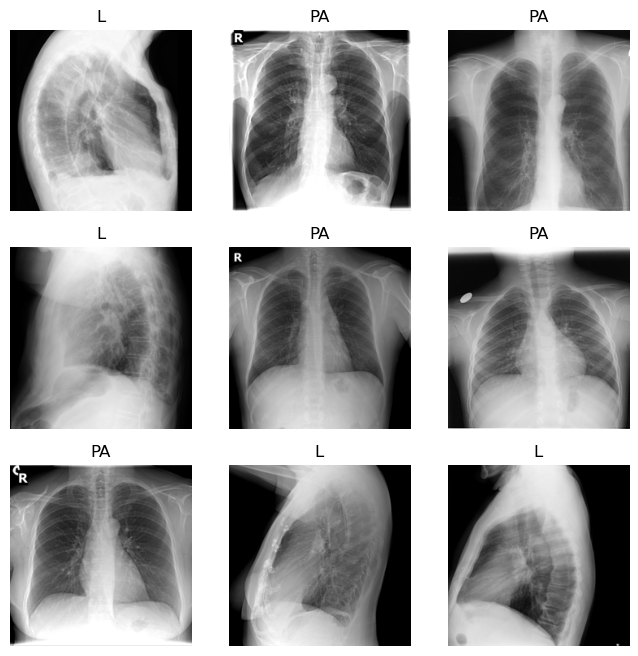

In [11]:
label_dict = {
    0: "PA",
    1: "L",
}

figure = plt.figure(figsize=(8, 8))
cols, rows = 3, 3
for i in range(1, cols * rows + 1):
    sample_idx = torch.randint(len(dataset), size=(1,)).item()
    img, label = dataset[sample_idx]
    figure.add_subplot(rows, cols, i)
    plt.title(label_dict[label])
    plt.axis("off")
    plt.imshow(img.squeeze(), cmap = 'gray')
plt.show()

<h1/> 2. Define the model, criterion and optimizer </h1>

<h2/> Option 1: Resnet-50 pretrained in ImageNet (freezing some layers)</h2>

In [4]:
# Load the model pretrained in ImageNet
model = models.resnet50(pretrained = True)

# Freeze the layers
for param in model.parameters():
    param.requires_grad = False

# Replace the first layer to receive 1-Channel images
model.conv1 = nn.Conv2d(1, 64, kernel_size=7, stride=2, padding=3, bias=False)

# Replace the FC layer with a classifier that has 2 classes
num_ftrs = model.fc.in_features
model.fc = nn.Linear(num_ftrs, 2)
model = model.to(DEVICE)

In [ ]:
criterion = nn.CrossEntropyLoss()
optim = torch.optim.Adam(model.parameters(), lr = 0.001, weight_decay = 1e-5, amsgrad = True)

<h2/> Option 2: Resnet-18 pretrained in ImageNet handling imbalanced classes with weighted loss</h2>

In [7]:
# Load the model pretrained in ImageNet
model = models.resnet18(pretrained = True)

# Replace the first layer to receive 1-Channel images
model.conv1 = nn.Conv2d(1, 64, kernel_size = 7, stride = 2, padding = 3, bias = False)

# Replace the FC layer with a classifier that has 2 classes
num_ftrs = model.fc.in_features
model.fc = nn.Linear(num_ftrs, 2)
model = model.to(DEVICE)

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /home/marialuque/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth
100%|██████████████████████████████████████| 44.7M/44.7M [00:04<00:00, 11.5MB/s]


In [8]:
criterion = nn.CrossEntropyLoss(weight = torch.FloatTensor([0.45, 0.55]).to(DEVICE))
optim = torch.optim.Adam(model.parameters(), lr = 0.001, weight_decay = 1e-5, amsgrad = True)

<h2/> Option 3: Resnet-50 pretrained in the same task: PA and L classification</h2>

In [5]:
# checkpoint = torch.load('./Models/'+'resnet-50.t7')
# model = checkpoint['model']

<h1/> 3. Train the model</h1>

In [9]:
def train_model(model, dataloaders, criterion, optimizer, num_epochs=20):
    since = time.time()

    best_model_wts = copy.deepcopy(model.state_dict())
    best_acc = 0.0

    for epoch in range(num_epochs):
        print(f'Epoch {epoch}/{num_epochs - 1}')
        print('-' * 10)

        # Each epoch has a training and validation phase
        for phase in ['train', 'val']:
            if phase == 'train':
                model.train()  # Set model to training mode
            else:
                model.eval()   # Set model to evaluate mode

            running_loss = 0.0
            running_corrects = 0

            # Iterate over data.
            for inputs, labels in dataloaders[phase]:
                inputs = inputs.to(DEVICE)
                labels = labels.to(DEVICE)

                # zero the parameter gradients
                optimizer.zero_grad()

                # forward
                # track history if only in train
                with torch.set_grad_enabled(phase == 'train'):
                    outputs = model(inputs)
                    _, preds = torch.max(outputs, 1)
                    loss = criterion(outputs, labels)
                    
                    # backward + optimize only if in training phase
                    if phase == 'train':
                        loss.backward()
                        optimizer.step()

                # statistics
                running_loss += loss.item() * inputs.size(0)
                running_corrects += torch.sum(preds == labels.data)

            epoch_loss = running_loss / dataset_sizes[phase]
            epoch_acc = running_corrects.double() / dataset_sizes[phase]
            
            if phase == 'train':
                writer.add_scalars('Loss', {'Loss/train': epoch_loss},epoch)
                writer.add_scalars('Accuracy',{'Accuracy/train':epoch_acc},epoch)

            
            elif phase == 'val':
                writer.add_scalars('Loss', {'Loss/val': epoch_loss},epoch)
                writer.add_scalars('Accuracy',{'Accuracy/val':epoch_acc},epoch)


            print(f'{phase} Loss: {epoch_loss:.4f} Acc: {epoch_acc:.4f}')

            # deep copy the model
            if phase == 'val' and epoch_acc > best_acc:
                best_acc = epoch_acc
                best_model_wts = copy.deepcopy(model.state_dict())
                torch.save(model, os.path.join('./Models/','resnet18_xrayView_PA_L.pth'))
                print('Model saved!')
        

        print()

    time_elapsed = time.time() - since
    print(f'Training complete in {time_elapsed // 60:.0f}m {time_elapsed % 60:.0f}s')
    print(f'Best val Acc: {best_acc:4f}')

    # load best model weights
    writer.flush()

In [10]:
train_model(model, dataloaders, criterion, optim, num_epochs = 20)

Epoch 0/19
----------
train Loss: 0.0351 Acc: 0.9925
val Loss: 0.0318 Acc: 0.9946
Model saved!

Epoch 1/19
----------
train Loss: 0.0263 Acc: 0.9947
val Loss: 0.0281 Acc: 0.9941

Epoch 2/19
----------
train Loss: 0.0244 Acc: 0.9949
val Loss: 0.0258 Acc: 0.9943

Epoch 3/19
----------
train Loss: 0.0233 Acc: 0.9950
val Loss: 0.0246 Acc: 0.9947
Model saved!

Epoch 4/19
----------
train Loss: 0.0224 Acc: 0.9953
val Loss: 0.0257 Acc: 0.9946

Epoch 5/19
----------
train Loss: 0.0221 Acc: 0.9953
val Loss: 0.0276 Acc: 0.9948
Model saved!

Epoch 6/19
----------
train Loss: 0.0214 Acc: 0.9955
val Loss: 0.0270 Acc: 0.9933

Epoch 7/19
----------
train Loss: 0.0203 Acc: 0.9956
val Loss: 0.0276 Acc: 0.9948

Epoch 8/19
----------
train Loss: 0.0198 Acc: 0.9956
val Loss: 0.0262 Acc: 0.9942

Epoch 9/19
----------
train Loss: 0.0188 Acc: 0.9957
val Loss: 0.0272 Acc: 0.9942

Epoch 10/19
----------
train Loss: 0.0184 Acc: 0.9958
val Loss: 0.0301 Acc: 0.9931

Epoch 11/19
----------
train Loss: 0.0176 Acc: 

<h1/>----------EVALUATION METRICS: MODEL RESNET-50----------</h1>

In [11]:
# Load model
model_resnet50 = torch.load(os.path.join('./Models/','resnet50_xrayView_PA_L.pth'))

In [12]:
# Obtain y_true and y_pred

# y_true: Ground truth (correct) target values.
# y_pred: Estimated targets as returned by a classifier.

model_resnet50.eval()
y_true = list()
y_pred = list()

with torch.no_grad():
    for test_data in test_loader:
        test_images, test_labels = (
            test_data[0].to(DEVICE),
            test_data[1].to(DEVICE),
        )
        pred = model_resnet50(test_images).argmax(dim=1)
        
        for i in range(len(pred)):
            y_true.append(test_labels[i].item())
            y_pred.append(pred[i].item())

<h2/>Accuracy, Precision, Recall and F1-Score</h2>

In [13]:
from sklearn.metrics import classification_report
class_names = ["PA","L"]
print(classification_report(y_true, y_pred, target_names = class_names, digits = 4))

              precision    recall  f1-score   support

          PA     0.9952    0.9956    0.9954     18284
           L     0.9919    0.9912    0.9915      9977

    accuracy                         0.9940     28261
   macro avg     0.9935    0.9934    0.9935     28261
weighted avg     0.9940    0.9940    0.9940     28261



<h2/>Confusion Matrix</h2>

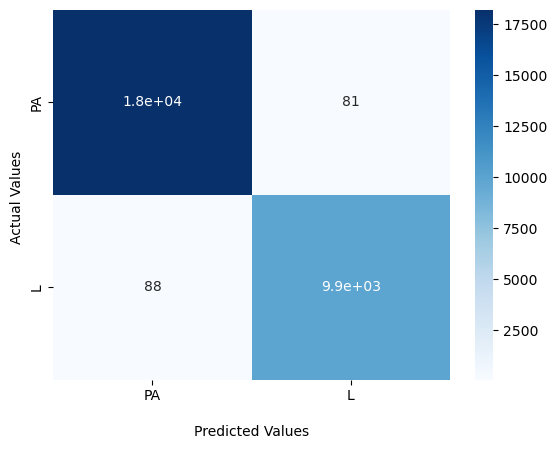

In [14]:
cmat = confusion_matrix(y_true, y_pred)
ax = sns.heatmap(cmat, annot=True, cmap='Blues')


ax.set_xlabel('\nPredicted Values')
ax.set_ylabel('Actual Values ');

## Ticket labels - List must be in alphabetical order
ax.xaxis.set_ticklabels(['PA','L'])
ax.yaxis.set_ticklabels(['PA','L'])

## Display the visualization of the Confusion Matrix.
plt.show()

In [15]:
tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
tn, fp, fn, tp 

(18203, 81, 88, 9889)

<h2/>Plot ROC-Curve and calculate AUC</h2>

In [23]:
# Obtain y_true and y_score

# y_true: Ground truth (correct) target values
# y_score: Probability estimates of the positive class

model_resnet50.eval()
y_true=list()
y_score= list()

with torch.no_grad():
    for test_data in test_loader:
        test_images, test_labels = (
            test_data[0].to(DEVICE),
            test_data[1].to(DEVICE),
        )
        pred = torch.softmax(model_resnet50(test_images), dim=1)[:, 1]
        
        for i in range(len(pred)):
            y_true.append(test_labels[i].item())
            y_score.append(pred[i].item())

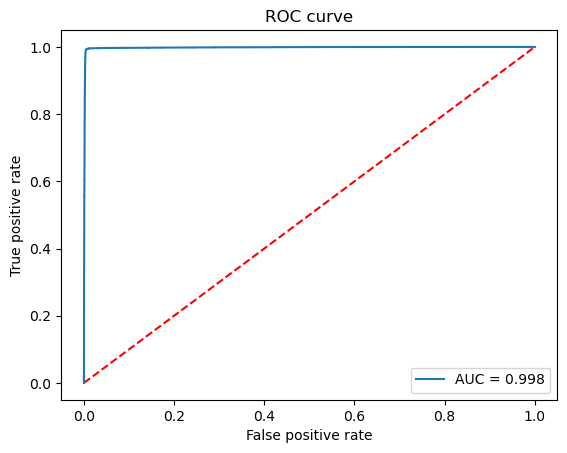

In [18]:
sklearn.metrics.roc_auc_score(y_true,y_score)
false_positive_rate, true_positive_rate, threshold = roc_curve(y_true,y_score)
area_under_curve = auc(false_positive_rate, true_positive_rate)

plt.plot([0, 1], [0, 1], 'r--')
plt.plot(false_positive_rate, true_positive_rate, label='AUC = {:.3f}'.format(area_under_curve))
plt.xlabel('False positive rate')
plt.ylabel('True positive rate')
plt.title('ROC curve')
plt.legend(loc='best')
plt.show()
#plt.savefig(ROC_PLOT_FILE, bbox_inches='tight')
plt.close()

<h1/>----------EVALUATION METRICS: MODEL RESNET-18----------</h1>

In [11]:
# Load model
model_resnet18 = torch.load(os.path.join('./Models/','resnet50_xrayView_PA_L.pth'))

In [13]:
# Obtain y_true and y_pred

# y_true: Ground truth (correct) target values.
# y_pred: Estimated targets as returned by a classifier.

model_resnet18.eval()
y_true = list()
y_pred = list()

with torch.no_grad():
    for test_data in test_loader:
        test_images, test_labels = (
            test_data[0].to(DEVICE),
            test_data[1].to(DEVICE),
        )
        pred = model_resnet18(test_images).argmax(dim=1)
        
        for i in range(len(pred)):
            y_true.append(test_labels[i].item())
            y_pred.append(pred[i].item())

<h2/>Accuracy, Precision, Recall and F1-Score</h2>

In [14]:
from sklearn.metrics import classification_report
class_names = ["PA","L"]
print(classification_report(y_true, y_pred, target_names = class_names, digits = 4))

              precision    recall  f1-score   support

          PA     0.9958    0.9962    0.9960     18294
           L     0.9930    0.9924    0.9927      9967

    accuracy                         0.9948     28261
   macro avg     0.9944    0.9943    0.9943     28261
weighted avg     0.9948    0.9948    0.9948     28261



<h2/>Confusion Matrix</h2>

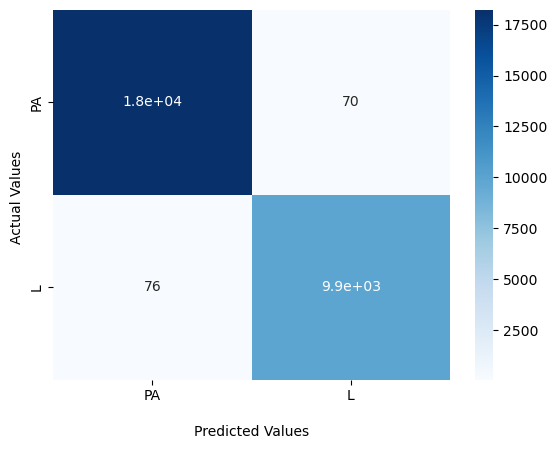

In [16]:
cmat = confusion_matrix(y_true, y_pred)
ax = sns.heatmap(cmat, annot=True, cmap='Blues')


ax.set_xlabel('\nPredicted Values')
ax.set_ylabel('Actual Values ');

## Ticket labels - List must be in alphabetical order
ax.xaxis.set_ticklabels(['PA','L'])
ax.yaxis.set_ticklabels(['PA','L'])

## Display the visualization of the Confusion Matrix.
plt.show()

In [17]:
tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
tn, fp, fn, tp 

(18224, 70, 76, 9891)

<h2/>Plot ROC-Curve and calculate AUC</h2>

In [18]:
# Obtain y_true and y_score

# y_true: Ground truth (correct) target values
# y_score: Probability estimates of the positive class

model_resnet18.eval()
y_true=list()
y_score= list()

with torch.no_grad():
    for test_data in test_loader:
        test_images, test_labels = (
            test_data[0].to(DEVICE),
            test_data[1].to(DEVICE),
        )
        pred = torch.softmax(model_resnet18(test_images), dim=1)[:, 1]
        
        for i in range(len(pred)):
            y_true.append(test_labels[i].item())
            y_score.append(pred[i].item())

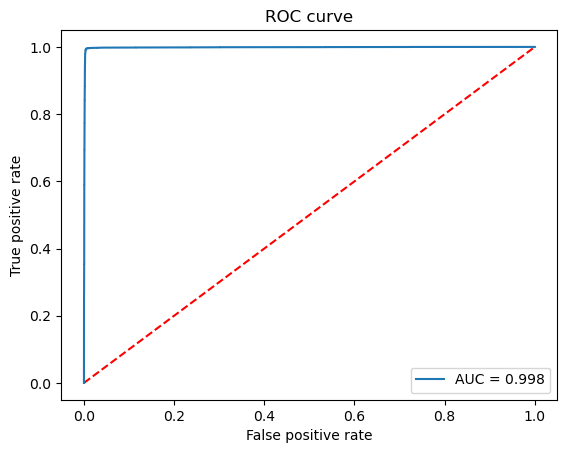

In [19]:
sklearn.metrics.roc_auc_score(y_true,y_score)
false_positive_rate, true_positive_rate, threshold = roc_curve(y_true,y_score)
area_under_curve = auc(false_positive_rate, true_positive_rate)

plt.plot([0, 1], [0, 1], 'r--')
plt.plot(false_positive_rate, true_positive_rate, label='AUC = {:.3f}'.format(area_under_curve))
plt.xlabel('False positive rate')
plt.ylabel('True positive rate')
plt.title('ROC curve')
plt.legend(loc='best')
plt.show()
#plt.savefig(ROC_PLOT_FILE, bbox_inches='tight')
plt.close()